# 01. 1D QCA → уравнение Дирака

**Проект «Структура и Данные»** — Notebook 01

Этот ноутбук строит простейший **квантовый клеточный автомат (QCA)** на 1D-цепочке и показывает, что в континуальном пределе он даёт уравнение Дирака.

**Что проверяется:**
1. Унитарность оператора шага (машинная точность)
2. Точная дисперсия: $\omega(k) = \arccos(\cos m \cdot \cos k)$
3. В пределе малых $k, m$: $\omega(k) \approx \sqrt{k^2 + m^2}$ (Дирак)

**Связь со статьёй:** §3
**Точность:** `float64`, ~$10^{-15}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"numpy version: {np.__version__}")
np.set_printoptions(precision=15, suppress=False)

numpy version: 2.4.6


In [2]:
# Параметры
L = 256          # длина цепочки
mass = 0.2       # параметр массы

# Монета (coin) — смешивание R/L компонент
def coin_operator(m):
    """Coin C = exp(-i m σ_x)."""
    c, s = np.cos(m), np.sin(m)
    return np.array([[c, -1j*s],
                     [-1j*s, c]], dtype=complex)

# Сдвиг в k-пространстве
def shift_k(k):
    """S(k) = diag(e^{-ik}, e^{+ik})."""
    return np.diag([np.exp(-1j*k), np.exp(1j*k)])

# Полная матрица шага в k-пространстве
def U_k(k, m):
    """U(k) = S(k) · C(m)."""
    return shift_k(k) @ coin_operator(m)

# Аналитическая и численная дисперсия
def omega_theory(k, m):
    """ω = arccos(cos m · cos k)."""
    return np.arccos(np.clip(np.cos(m) * np.cos(k), -1.0, 1.0))

def omega_numeric(k, m):
    """Из собственных значений U(k)."""
    U = U_k(k, m)
    eigs = np.linalg.eigvals(U)
    return np.abs(np.angle(eigs)).min()

# Демонстрация: монета
C = coin_operator(mass)
print("Coin operator C:")
print(C)
print(f"\n||C†C - I|| = {np.max(np.abs(C.conj().T @ C - np.eye(2))):.2e}")

Coin operator C:
[[0.980066577841242+0.j
  0.               -0.198669330795061j]
 [0.               -0.198669330795061j
  0.980066577841242+0.j               ]]

||C†C - I|| = 0.00e+00


In [3]:
k_test = np.linspace(-np.pi, np.pi, 1000)
unitarity_errors = []
for k in k_test:
    U = U_k(k, mass)
    err = np.max(np.abs(U.conj().T @ U - np.eye(2)))
    unitarity_errors.append(err)

max_unit_err = np.max(unitarity_errors)
print(f"Max ||U†U - I|| over 1000 k values: {max_unit_err:.2e}")
print(f"Status: {'✅ UNITARY' if max_unit_err < 1e-14 else '❌ NOT UNITARY'}")

Max ||U†U - I|| over 1000 k values: 2.22e-16
Status: ✅ UNITARY


In [4]:
k_vals = np.linspace(-np.pi, np.pi, 200)
omega_th = np.array([omega_theory(k, mass) for k in k_vals])
omega_num = np.array([omega_numeric(k, mass) for k in k_vals])

max_err = np.max(np.abs(omega_th - omega_num))
print(f"Max |ω_theory - ω_numeric| = {max_err:.2e}")
print(f"Status: {'✅ PASS' if max_err < 1e-13 else '❌ FAIL'}")

print(f"\nKey points (m = {mass}):")
print(f"{'k':>8} {'ω_theory':>15} {'ω_numeric':>15} {'diff':>12}")
print('-' * 55)
for k in [0, 0.5, np.pi/2, 1.5, np.pi]:
    w_th = omega_theory(k, mass)
    w_num = omega_numeric(k, mass)
    print(f"{k:>8.4f} {w_th:>15.10f} {w_num:>15.10f} {abs(w_th-w_num):>12.2e}")

# Предел Дирака
print(f"\nSmall-k limit (m = {mass}):")
print(f"{'k':>8} {'ω_QCA':>15} {'√(k²+m²)':>15} {'rel. err':>12}")
print('-' * 55)
for k in [0.01, 0.05, 0.10, 0.20, 0.30, 0.50]:
    w_qca = omega_theory(k, mass)
    w_dirac = np.sqrt(k**2 + mass**2)
    rel_err = abs(w_qca - w_dirac) / w_dirac
    print(f"{k:>8.2f} {w_qca:>15.8f} {w_dirac:>15.8f} {rel_err:>12.2e}")

Max |ω_theory - ω_numeric| = 8.88e-16
Status: ✅ PASS

Key points (m = 0.2):
       k        ω_theory       ω_numeric         diff
-------------------------------------------------------
  0.0000    0.2000000000    0.2000000000     5.55e-17
  0.5000    0.5353515565    0.5353515565     1.11e-16
  1.5708    1.5707963268    1.5707963268     0.00e+00
  1.5000    1.5014135052    1.5014135052     0.00e+00
  3.1416    2.9415926536    2.9415926536     0.00e+00

Small-k limit (m = 0.2):
       k           ω_QCA        √(k²+m²)     rel. err
-------------------------------------------------------
    0.01      0.20024651      0.20024984     1.67e-05
    0.05      0.20607419      0.20615528     3.93e-04
    0.10      0.22330746      0.22360680     1.34e-03
    0.20      0.28189328      0.28284271     3.36e-03
    0.30      0.35887265      0.36055513     4.67e-03
    0.50      0.53535156      0.53851648     5.88e-03


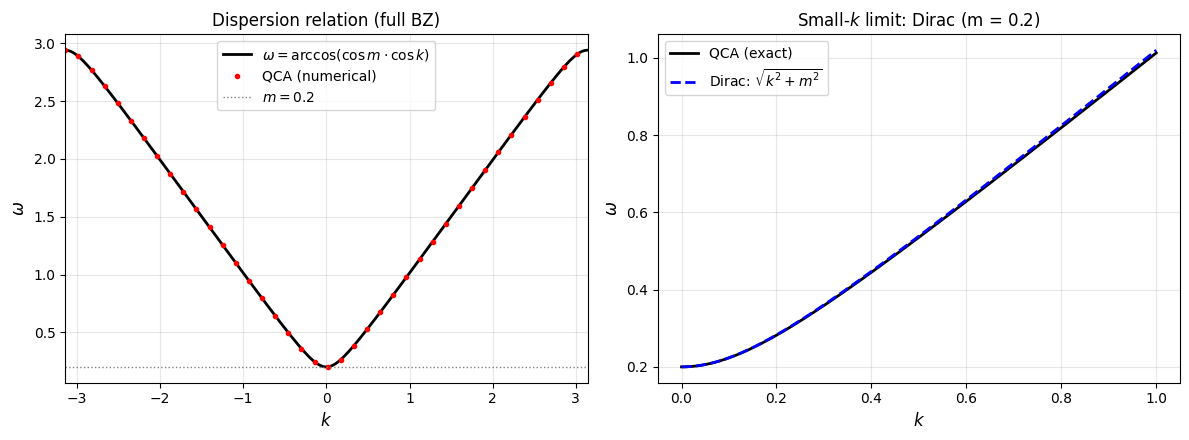

✅ Figure saved: 01_dirac_dispersion.png
📥 Скачать: см. следующую ячейку


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --- Левая панель: полная дисперсия ---
axes[0].plot(k_vals, omega_th, 'k-', lw=2, label=r'$\omega = \arccos(\cos m \cdot \cos k)$')
axes[0].plot(k_vals, omega_num, 'ro', ms=3, markevery=5, label='QCA (numerical)')
axes[0].axhline(mass, color='gray', ls=':', lw=1, label=f'$m = {mass}$')
axes[0].set_xlabel('$k$', fontsize=12)
axes[0].set_ylabel(r'$\omega$', fontsize=12)
axes[0].set_title('Dispersion relation (full BZ)', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].set_xlim(-np.pi, np.pi)

# --- Правая панель: предел Дирака ---
k_dirac = np.linspace(0, 1, 200)
w_qca_lim = np.array([omega_theory(k, mass) for k in k_dirac])
w_dirac = np.sqrt(k_dirac**2 + mass**2)

axes[1].plot(k_dirac, w_qca_lim, 'k-', lw=2, label='QCA (exact)')
axes[1].plot(k_dirac, w_dirac, 'b--', lw=2, label=r'Dirac: $\sqrt{k^2 + m^2}$')
axes[1].set_xlabel('$k$', fontsize=12)
axes[1].set_ylabel(r'$\omega$', fontsize=12)
axes[1].set_title(f'Small-$k$ limit: Dirac (m = {mass})', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('01_dirac_dispersion.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Figure saved: 01_dirac_dispersion.png")
print("📥 Скачать: см. следующую ячейку")

In [6]:
# Скачивает файл на ваш компьютер
from google.colab import files
files.download('01_dirac_dispersion.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>